# Player-vs-player matrix for NMF

The aim is to factorise a **player × player matrix** with NMF
(non-negative matrix factorisation). This first step builds the matrix and
checks how much of it is filled in, which decides whether NMF is workable.

- **Players**: the 100 players with the most ATP tour-level matches in
  2024, i.e. the busiest players going into 2025.
- **Cells**: the number of matches each pair played against each other in
  2025 (calendar year). The matrix is symmetric, and the diagonal (a player
  against himself) is always empty.

Data: the tennis-data.co.uk files in `atp_data/`, as in
`elo_prediction.ipynb`.

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*xlrd.*")
warnings.filterwarnings("ignore", message="Unknown extension")
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

files = [os.path.join("atp_data", f"{year}.xlsx") for year in (2024, 2025, 2026)]
raw = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)

# Drop matches that weren't played (walkovers etc.); retirements count.
matches = raw[~raw["Comment"].isin(["Walkover", "Awarded", "Sched"])].copy()

# Merge alternative spellings of a name ("Carreno-Busta P." and
# "Carreno Busta P."), using each player's most common spelling.
names = pd.concat([matches["Winner"], matches["Loser"]]).str.strip()
key = names.str.lower().str.replace(r"[^a-z]", "", regex=True)
canonical = (pd.DataFrame({"name": names, "key": key})
             .groupby("key")["name"].agg(lambda n: n.value_counts().index[0]))
for side in ("Winner", "Loser"):
    matches[side] = (matches[side].str.strip().str.lower()
                     .str.replace(r"[^a-z]", "", regex=True).map(canonical))
matches["Year"] = matches["Date"].dt.year
print(matches.groupby("Year").size().to_string())

Year
2023       2
2024    2709
2025    2594
2026    2345


The season files overlap calendar years slightly (the 2025 file starts on
29 December 2024), so matches are assigned to years by their date.

## 1. The 100 busiest players of 2024

In [2]:
in_2024 = matches[matches["Year"] == 2024]
played_2024 = pd.concat([in_2024["Winner"], in_2024["Loser"]]).value_counts()
top = played_2024.head(100)
players = list(top.index)
print(f"{len(played_2024)} players played in 2024; the top 100 played "
      f"{top.min()}-{top.max()} matches (median {top.median():.0f})")
print(f"Players on exactly {top.min()} matches: "
      f"{(played_2024 == top.min()).sum()} in total, "
      f"{(top == top.min()).sum()} of them included")
top.head(10)

291 players played in 2024; the top 100 played 20-79 matches (median 44)
Players on exactly 20 matches: 2 in total, 2 of them included


Zverev A.       79
Sinner J.       76
Rune H.         69
Rublev A.       68
Fritz T.        67
Ruud C.         65
Dimitrov G.     64
Shelton B.      64
Medvedev D.     62
De Minaur A.    62
Name: count, dtype: int64

## 2. The matrix: matches between each pair in 2025

In [3]:
in_2025 = matches[(matches["Year"] == 2025)
                  & matches["Winner"].isin(players)
                  & matches["Loser"].isin(players)]
index = {p: i for i, p in enumerate(players)}
matrix = np.zeros((len(players), len(players)), dtype=int)
for w, l in zip(in_2025["Winner"], in_2025["Loser"]):
    matrix[index[w], index[l]] += 1
    matrix[index[l], index[w]] += 1
matrix = pd.DataFrame(matrix, index=players, columns=players)

all_2025 = matches[matches["Year"] == 2025]
involved = all_2025["Winner"].isin(players) | all_2025["Loser"].isin(players)
print(f"2025 matches: {len(all_2025):,} in total, {involved.sum():,} involving "
      f"at least one of the 100, {len(in_2025):,} between two of them")
matrix.iloc[:8, :8]

2025 matches: 2,594 in total, 2,348 involving at least one of the 100, 1,322 between two of them


,Zverev A.,Sinner J.,Rune H.,Rublev A.,Fritz T.,Ruud C.,Dimitrov G.,Shelton B.
Zverev A.,0,4,0,0,1,0,0,4
Sinner J.,4,0,1,1,0,1,1,4
Rune H.,0,1,0,0,0,1,0,0
Rublev A.,0,1,0,0,1,0,0,1
Fritz T.,1,0,0,1,0,1,0,1
Ruud C.,0,1,1,0,1,0,0,0
Dimitrov G.,0,1,0,0,0,0,0,0
Shelton B.,4,4,0,1,1,0,0,0


## 3. How much of the matrix is filled in

The matrix has 100 × 100 = 10,000 cells. The 100 diagonal cells can never
be filled, and every pair appears twice (row A column B, and row B column
A), so the real question is how many of the **4,950 distinct pairs** played
each other at least once.

In [4]:
n = len(players)
pairs = n * (n - 1) // 2
upper = matrix.to_numpy()[np.triu_indices(n, k=1)]
filled = (upper > 0).sum()
print(f"Distinct pairs:             {pairs:,}")
print(f"Pairs that played in 2025:  {filled:,} ({filled / pairs:.1%})")
print(f"Pairs that didn't:          {pairs - filled:,} "
      f"({1 - filled / pairs:.1%})")
print(f"Of all 10,000 cells:        {(matrix.to_numpy() > 0).sum():,} filled "
      f"({(matrix.to_numpy() > 0).mean():.1%})")
print("\nMatches per filled pair:")
print(pd.Series(upper[upper > 0]).value_counts().sort_index()
      .rename_axis("matches").to_frame("pairs").T.to_string())

Distinct pairs:             4,950
Pairs that played in 2025:  1,065 (21.5%)
Pairs that didn't:          3,885 (78.5%)
Of all 10,000 cells:        2,130 filled (21.3%)

Matches per filled pair:
matches    1    2   3  4  6
pairs    867  151  37  9  1


In [5]:
opponents = (matrix > 0).sum(axis=1)
played_2025 = matrix.sum(axis=1)
summary = pd.DataFrame({"matches_2024": top,
                        "matches_v_top100_2025": played_2025,
                        "distinct_top100_opponents": opponents})
print(f"Distinct top-100 opponents per player in 2025: "
      f"median {opponents.median():.0f}, range "
      f"{opponents.min()}-{opponents.max()}")
print(f"Players with no 2025 match against the others: "
      f"{(played_2025 == 0).sum()}")
summary.sort_values("distinct_top100_opponents").head(8)

Distinct top-100 opponents per player in 2025: median 22, range 0-41
Players with no 2025 match against the others: 3


,matches_2024,matches_v_top100_2025,distinct_top100_opponents
Kotov P.,40,0,0
Purcell M.,34,0,0
Van Assche L.,23,0,0
Monteiro T.,20,1,1
Coric B.,29,2,2
Coria F.,23,2,2
Koepfer D.,31,2,2
Ruusuvuori E.,28,2,2


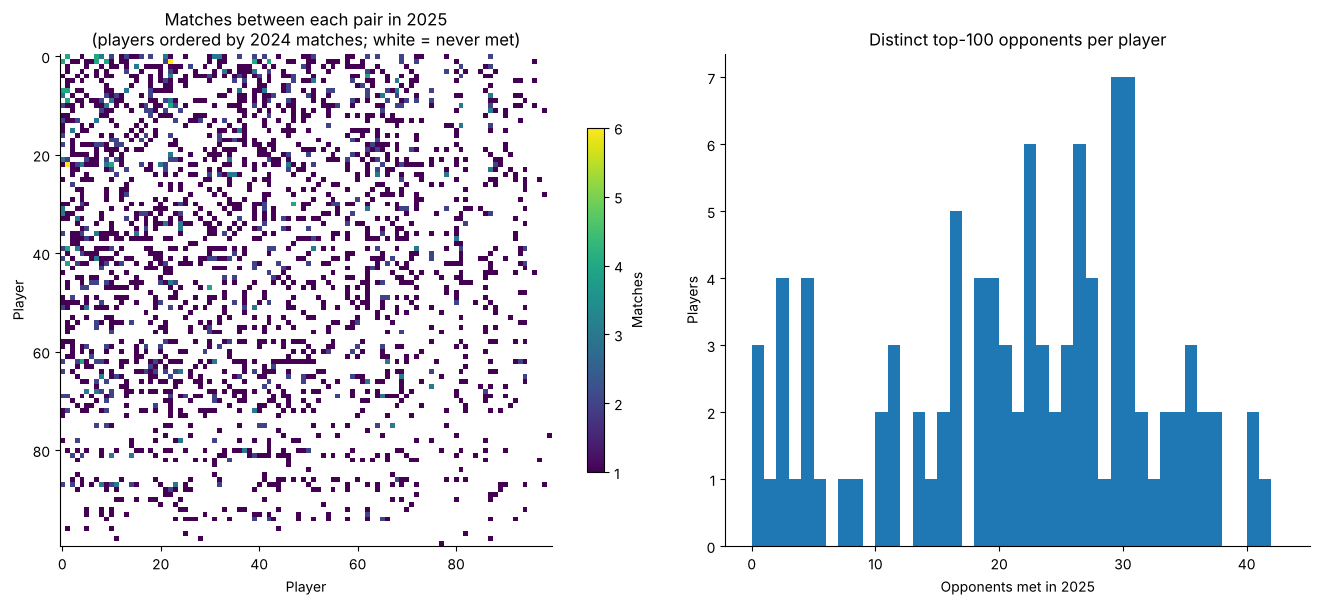

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(np.where(matrix > 0, matrix, np.nan), cmap="viridis",
                    interpolation="nearest")
axes[0].set_title("Matches between each pair in 2025\n"
                  "(players ordered by 2024 matches; white = never met)")
axes[0].set_xlabel("Player")
axes[0].set_ylabel("Player")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="Matches")
axes[1].hist(opponents, bins=range(0, opponents.max() + 3))
axes[1].set_title("Distinct top-100 opponents per player")
axes[1].set_xlabel("Opponents met in 2025")
axes[1].set_ylabel("Players")
plt.tight_layout()

## What this means for NMF

**About a fifth of the matrix is filled in**: 1,065 of the 4,950 pairs
(21.5%) played each other at least once in 2025, and most of those only
once. Nearly 80% of the cells are zero, and a few players (for example
those who missed 2025 through a ban or injury) have empty rows.

That matters for NMF, because a zero here doesn't mean "these two players
have nothing in common": it usually just means the draw never put them
together. Plain NMF treats every zero as a real value, so on this matrix it
would mostly learn **who plays the same tournaments and goes deep in them**
(top players meet each other in later rounds; lower-ranked players meet in
early rounds and at smaller events). That can be a useful segmentation in
itself (e.g. tour level and schedule), but not of playing styles.

Options, depending on what the factors should capture:

- **Fill more of the matrix**: combine several seasons (e.g. 2023-2025).
- **Masked NMF**: fit only the cells where a pair actually met, and treat
  the rest as unknown rather than zero.
- **A different cell value**: e.g. wins of the row player against the
  column player (not symmetric), or games won, to capture match-ups rather
  than how often players meet.